# Data preparation and forecasting cohorts

The primary cohort supports prediction from cycle 10. The prefix experiment uses
a common eligible cohort across landmarks. This notebook shows their observation
status and provides the preparation command for authorized laboratory data.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:06:46+00:00
Inputs: included aggregate tables and public external extracts


## Cohorts and observation status

,cohort,tests,sites,events,known_non_events,unresolved
0,Primary N0=10,812,13,490,263,59
1,Common prefix cohort,788,13,466,263,59


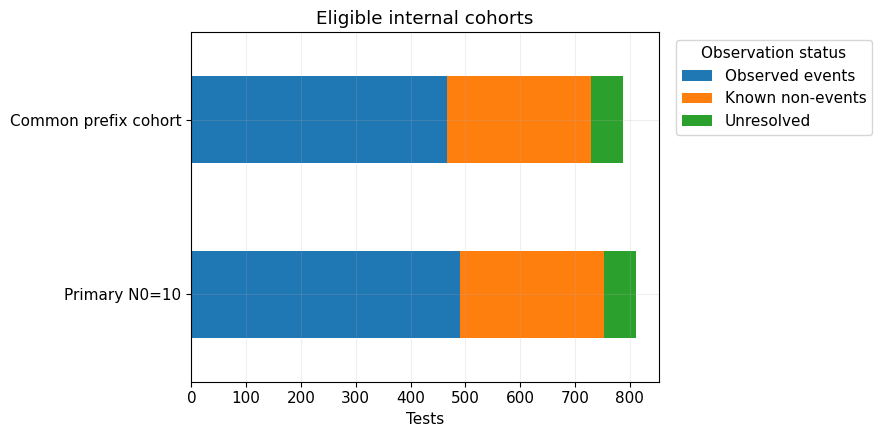

In [2]:
cohorts = pd.read_csv(TABLES / "cohort_counts.csv")
display(cohorts)
fig, ax = plt.subplots()
cohorts.set_index("cohort")[["events", "known_non_events", "unresolved"]].rename(columns={"events":"Observed events", "known_non_events":"Known non-events", "unresolved":"Unresolved"}).plot.barh(stacked=True, ax=ax)
ax.set(xlabel="Tests", ylabel="", title="Eligible internal cohorts")
ax.legend(title="Observation status", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout(); plt.show()

## Public external inputs

External cycle-level extracts and original download links are in `data/external/SOURCES.md`. Notebook 4.1 reads and checks them.

## Prepare the laboratory data

Set `LIQ_REAL_ROOT` to an authorized archive outside Git, then enable
`PREPARE_PRIVATE_DATA` below. Preparation constructs prefixes before smoothing
and excludes the end cycle from the predictors.

In [3]:
PREPARE_PRIVATE_DATA = False
if PREPARE_PRIVATE_DATA:
    import os
    from dpi_evt.experiments.final_run import prepare_populations, preflight
    raw = os.environ.get("LIQ_REAL_ROOT")
    if not raw:
        raise RuntimeError("Set LIQ_REAL_ROOT to the authorized laboratory archive first.")
    display(prepare_populations(ROOT, raw_root=raw))
    display(preflight(ROOT, deep=True))
else:
    print("Set PREPARE_PRIVATE_DATA=True to prepare the authorized laboratory archive.")

Set PREPARE_PRIVATE_DATA=True to prepare the authorized laboratory archive.
